In [1]:
from pathlib import Path
from contextlib import closing
import json
import re
import sqlite3

import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RAW, PROCESSED, DB = ROOT / "data/raw", ROOT / "data/processed", ROOT / "data/coffee.db"
TABLES = ROOT / "docs/raport-cw2/tables"
TABLES.mkdir(parents=True, exist_ok=True)
START, END = 2000, 2023
pd.set_option("display.max_rows", 80, "display.max_colwidth", 200)


def query(sql):
    with closing(sqlite3.connect(f"file:{DB.as_posix()}?mode=ro", uri=True)) as con:
        return pd.read_sql(sql, con)


def number(value, decimals=0):
    return f"{value:,.{decimals}f}".replace(",", " ").replace(".", ",")


def save_table(frame, name):
    (TABLES / f"{name}.md").write_text(frame.to_markdown(index=False) + "\n", encoding="utf-8")
    display(frame)

In [2]:
manifest = json.loads((RAW / "sources.json").read_text(encoding="utf-8"))
qcl = pd.read_csv(PROCESSED / "faostat_coffee_all.csv", dtype={"Area Code (M49)": "string"})
tcl = pd.read_csv(PROCESSED / "faostat_trade_coffee.csv", dtype={"Area Code (M49)": "string"})
era5 = json.loads((RAW / manifest["worldbank"]["path"]).read_text(encoding="utf-8"))["data"]
era5_years = [int(timestamp[:4]) for series in era5["tas"].values() for timestamp in series]
pink_sheet = pd.read_excel(RAW / manifest["pink_sheet"]["path"], "Annual Prices (Nominal)", header=6, skiprows=[7])
cpi = json.loads((RAW / manifest["cpi_usa"]["path"]).read_text(encoding="utf-8"))[1]
m49_table = re.search(r'<table\b[^>]*id\s*=\s*"downloadTableEN"[^>]*>(.*?)</table>',
                      (RAW / manifest["un_m49"]["path"]).read_text(encoding="utf-8"), re.S).group(1)
m49_iso3 = re.findall(r"<td[^>]*>\s*([A-Z]{3})\s*</td>", m49_table)
m49_columns = max(len(re.findall(r"<td\b", row)) for row in re.findall(r"<tr\b[^>]*>(.*?)</tr>", m49_table, re.S))
ico = pd.read_excel(RAW / manifest["ico_production"]["path"], header=None)
ico_countries = int(ico[1].astype(str).str.fullmatch(r"\((A|R|A/R|R/A)\)").sum())
optimum = pd.read_csv(RAW / manifest["weather_optimum"]["path"])


def years(values):
    return f"{min(values)}–{max(values)}"


def fao_areas(frame):
    return frame.loc[frame["Area Code"].lt(5000), "Area"].nunique()


sources = pd.DataFrame([
    ["FAOSTAT QCL – zbiory (wycinek: kawa)", "CSV w ZIP", f"{number(len(qcl))} × {qcl.shape[1]}",
     "Area Code + Element + Year", years(qcl["Year"]), fao_areas(qcl), "t, ha, kg/ha"],
    ["FAOSTAT TCL – eksport (wycinek: kawa)", "CSV w ZIP", f"{number(len(tcl))} × {tcl.shape[1]}",
     "Area Code + Element Code + Year", years(tcl["Year"]), fao_areas(tcl), "t, 1000 USD"],
    ["World Bank CCKP / ERA5 – pogoda", "JSON (API)", f"{len(era5['tas'])} × {len(set(era5_years))} × {len(era5)}",
     "ISO3 + rok + zmienna", years(era5_years), len(era5["tas"]), "°C, mm"],
    ["World Bank Pink Sheet – ceny", "XLSX", f"{len(pink_sheet)} × {pink_sheet.shape[1]}",
     "rok", years(pink_sheet.iloc[:, 0]), "świat", "USD/kg"],
    ["World Bank WDI – CPI USA", "JSON (API)", f"{len(cpi)} × 2",
     "rok", years([int(row["date"]) for row in cpi]), "USA", "indeks, 2010 = 100"],
    ["UN M49 – kody krajów", "HTML", f"{len(m49_iso3)} × {m49_columns}", "kod M49 → ISO3", "–", len(m49_iso3), "–"],
    ["ICO – gatunek kawy", "XLSX", f"{ico_countries} × {ico.shape[1]}", "nazwa kraju",
     f"{ico.iloc[3, 2]}–{ico.iloc[3, ico.shape[1] - 1]}", ico_countries, "typ A, R, A/R, R/A"],
    ["Literatura – optimum pogody", "CSV (ręcznie)", f"{len(optimum)} × {optimum.shape[1]}", "gatunek", "–", "–", "°C, mm"],
], columns=["źródło", "format", "rozmiar (wiersze × kolumny)", "klucz", "lata", "kraje", "jednostki"])
save_table(sources, "sources")

C:\Users\chame\studia\sem7\systemy-analizy-biznesowej\projekt\systemy-analizy-biznesowej-projekt\.venv\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


,źródło,format,rozmiar (wiersze × kolumny),klucz,lata,kraje,jednostki
0,FAOSTAT QCL – zbiory (wycinek: kawa),CSV w ZIP,20 209 × 14,Area Code + Element + Year,1961–2024,86,"t, ha, kg/ha"
1,FAOSTAT TCL – eksport (wycinek: kawa),CSV w ZIP,25 219 × 9,Area Code + Element Code + Year,1961–2024,204,"t, 1000 USD"
2,World Bank CCKP / ERA5 – pogoda,JSON (API),246 × 76 × 2,ISO3 + rok + zmienna,1950–2025,246,"°C, mm"
3,World Bank Pink Sheet – ceny,XLSX,66 × 70,rok,1960–2025,świat,USD/kg
4,World Bank WDI – CPI USA,JSON (API),24 × 2,rok,2000–2023,USA,"indeks, 2010 = 100"
5,UN M49 – kody krajów,HTML,248 × 16,kod M49 → ISO3,–,248,–
6,ICO – gatunek kawy,XLSX,54 × 32,nazwa kraju,1990/91–2019/20,54,"typ A, R, A/R, R/A"
7,Literatura – optimum pogody,CSV (ręcznie),2 × 6,gatunek,–,–,"°C, mm"


In [3]:
model = query("""
    SELECT k.iso3, k.year, k.production_t, k.yield_kg_ha, k.k1_export_t AS export_t,
           k.k2_export_value_usd AS export_value_usd, k.k3_usd_per_kg AS usd_per_kg,
           k.k6_usd_2023_per_kg AS usd_2023_per_kg, k.temperature_c, k.precipitation_mm,
           y.arabica_usd_kg, y.robusta_usd_kg
    FROM v_kpi_country_year AS k JOIN dim_year AS y USING (year)""")


def short(value):
    return number(value, 2) if isinstance(value, float) else value


profile = pd.DataFrame([{
    "kolumna": column,
    "typ": "liczba" if pd.api.types.is_numeric_dtype(values) else "tekst",
    "braki [%]": round(values.isna().mean() * 100, 1),
    "unikalne": values.nunique(),
    "min": short(values.min()),
    "mediana": short(float(values.median())) if pd.api.types.is_numeric_dtype(values) else "–",
    "max": short(values.max()),
} for column, values in model.items()])
save_table(profile, "profile")

,kolumna,typ,braki [%],unikalne,min,mediana,max
0,iso3,tekst,0.0,51,BDI,–,ZWE
1,year,liczba,0.0,24,2000,"2 011,50",2023
2,production_t,liczba,0.0,1165,"1,18","32 035,00","3 705 719,00"
3,yield_kg_ha,liczba,0.0,1132,"82,20","647,20","3 915,80"
4,export_t,liczba,0.0,1165,"0,00","11 141,27","2 372 632,78"
5,export_value_usd,liczba,0.0,1163,"0,00","18 212 000,00","8 514 139 000,00"
6,usd_per_kg,liczba,1.7,1186,"0,29","2,67","125,00"
7,usd_2023_per_kg,liczba,1.7,1203,"0,36","3,58","155,38"
8,temperature_c,liczba,0.0,644,"6,63","24,20","27,75"
9,precipitation_mm,liczba,0.0,1222,"93,16","1 570,54","4 897,40"


In [4]:
RULES = [
    ("R1", "(iso3, year) unikalne i niepuste", "krytyczny", "schemat: PRIMARY KEY",
     "SELECT iso3, year FROM fact_country_year GROUP BY iso3, year HAVING COUNT(*) > 1 OR iso3 IS NULL OR year IS NULL"),
    ("R2", "iso3 i year z faktów istnieją w wymiarach", "krytyczny", "schemat: FOREIGN KEY",
     """SELECT f.iso3, f.year FROM fact_country_year AS f
        LEFT JOIN dim_country AS c USING (iso3) LEFT JOIN dim_year AS y USING (year)
        WHERE c.iso3 IS NULL OR y.year IS NULL"""),
    ("R3", "zbiory i eksport w t, wartość w 1000 USD", "krytyczny", "assert na kolumnie Unit przed ładowaniem", None),
    ("R4", "zbiory, eksport i wartość ≥ 0", "krytyczny", "schemat: CHECK",
     "SELECT iso3, year FROM fact_country_year WHERE production_t < 0 OR export_t < 0 OR export_value_usd < 0"),
    ("R5", "eksport (wolumen i wartość) we wszystkich 24 latach", "wysoki", "notebook 02: wykluczenie kraju",
     "SELECT iso3, NULL AS year FROM fact_country_year GROUP BY iso3 HAVING COUNT(export_t) < 24 OR COUNT(export_value_usd) < 24"),
    ("R6", "każdy rok ma CPI i obie ceny", "wysoki", "schemat: NOT NULL",
     "SELECT NULL AS iso3, year FROM dim_year WHERE cpi_usa IS NULL OR arabica_usd_kg IS NULL OR robusta_usd_kg IS NULL"),
    ("R7", "K3 tylko przy wolumenie > 0; K4 i K5 tylko przy podstawie > 0", "wysoki", "widok: NULLIF",
     """SELECT iso3, year FROM (
            SELECT *, LAG(k1_export_t) OVER w AS previous_t, LAG(k2_export_value_usd) OVER w AS previous_usd
            FROM v_kpi_country_year WINDOW w AS (PARTITION BY iso3 ORDER BY year))
        WHERE (k1_export_t = 0 AND k3_usd_per_kg IS NOT NULL)
           OR (previous_t = 0 AND k4_export_t_yoy_pct IS NOT NULL)
           OR (previous_usd = 0 AND k5_export_value_yoy_pct IS NOT NULL)"""),
    ("R8", "zmiana r/r zbiorów lub eksportu powyżej ±50%", "średni", "zapytanie kontrolne → flaga",
     "SELECT iso3, year FROM v_kpi_country_year WHERE ABS(production_yoy_pct) > 50 OR ABS(k4_export_t_yoy_pct) > 50"),
    ("R9", "eksport większy niż zbiory", "średni", "zapytanie kontrolne → flaga",
     "SELECT iso3, year FROM fact_country_year WHERE export_t > production_t"),
    ("R10", "K3 poza 0,5–2 × cena referencyjna gatunku (próg wstępny)", "średni", "zapytanie kontrolne → przegląd",
     "SELECT iso3, year FROM v_kpi_country_year WHERE k3_usd_per_kg NOT BETWEEN 0.5 * reference_usd_kg AND 2 * reference_usd_kg"),
    ("R11", "plon ≈ zbiory / powierzchnia (±5%)", "niski", "zapytanie kontrolne → flaga",
     "SELECT iso3, year FROM fact_country_year WHERE area_ha > 0 AND ABS(yield_kg_ha - production_t / area_ha * 1000) > 0.05 * yield_kg_ha"),
]
summary, flagged = [], []
for rule, description, priority, enforcement, sql in RULES:
    rows = query(sql) if sql else None
    if rows is not None and len(rows):
        flagged.append(rows.assign(rule=rule))
    summary.append({"ID": rule, "reguła": description, "priorytet": priority, "egzekwowanie": enforcement,
                    "naruszenia [wiersze]": "–" if rows is None else len(rows)})
rules = pd.DataFrame(summary)
blocking = rules.loc[rules["priorytet"].isin(["krytyczny", "wysoki"]) & rules["naruszenia [wiersze]"].ne("–")]
assert blocking["naruszenia [wiersze]"].eq(0).all(), blocking
countries = query("SELECT iso3, country FROM dim_country")
review = pd.concat(flagged).merge(countries, on="iso3", how="left")[["rule", "iso3", "country", "year"]]
review.to_csv(PROCESSED / "dq_review.csv", index=False)
save_table(rules, "dq_rules")
display(review.groupby("rule").agg(rows=("iso3", "size"), countries=("iso3", "nunique")))

,ID,reguła,priorytet,egzekwowanie,naruszenia [wiersze]
0,R1,"(iso3, year) unikalne i niepuste",krytyczny,schemat: PRIMARY KEY,0
1,R2,iso3 i year z faktów istnieją w wymiarach,krytyczny,schemat: FOREIGN KEY,0
2,R3,"zbiory i eksport w t, wartość w 1000 USD",krytyczny,assert na kolumnie Unit przed ładowaniem,–
3,R4,"zbiory, eksport i wartość ≥ 0",krytyczny,schemat: CHECK,0
4,R5,eksport (wolumen i wartość) we wszystkich 24 latach,wysoki,notebook 02: wykluczenie kraju,0
5,R6,każdy rok ma CPI i obie ceny,wysoki,schemat: NOT NULL,0
6,R7,K3 tylko przy wolumenie > 0; K4 i K5 tylko przy podstawie > 0,wysoki,widok: NULLIF,0
7,R8,zmiana r/r zbiorów lub eksportu powyżej ±50%,średni,zapytanie kontrolne → flaga,309
8,R9,eksport większy niż zbiory,średni,zapytanie kontrolne → flaga,152
9,R10,"K3 poza 0,5–2 × cena referencyjna gatunku (próg wstępny)",średni,zapytanie kontrolne → przegląd,150


,rows,countries
rule,,
R10,150,21
R11,1,1
R8,309,40
R9,152,25


In [5]:
fact = query("SELECT * FROM fact_country_year")
kpi = query("SELECT * FROM v_kpi_country_year")
kpi_country = query("SELECT * FROM v_kpi_country")
excluded = pd.read_csv(PROCESSED / "excluded_export_countries.csv")
n_countries = fact["iso3"].nunique()


def violations(rule):
    return rules.loc[rules["ID"].eq(rule), "naruszenia [wiersze]"].item()


def estimated(flags):
    return f"{flags.ne('A').mean() * 100:.0f}%"


zero_export = kpi.loc[kpi["k1_export_t"].eq(0)]
no_species = kpi_country.loc[kpi_country["species"].isna(), "country"]
never_in_optimum = (kpi.dropna(subset=["species"]).groupby(["species", "iso3"])["weather_in_optimum"].max().eq(0)
                    .groupby("species").agg(lambda s: f"{s.sum()} z {len(s)}"))
countries_dim = query("SELECT * FROM dim_country")
filled = countries_dim.loc[countries_dim["species"].notna() & countries_dim["species_source"].ne("ICO"), "country"]
usa = fact.loc[fact["iso3"].eq("USA"), ["export_t", "production_t"]].mean()
updated = {name: manifest[name]["last_updated"][:10] for name in ["faostat", "faostat_trade", "pink_sheet", "cpi_usa"]}

quality = pd.DataFrame([
    ["kompletność",
     f"{len(excluded)} z {len(excluded) + n_countries} producentów nie ma eksportu we wszystkich latach {START}–{END}; "
     f"największy udział wykluczonego kraju w światowym eksporcie to {number(excluded['max_world_export_share_pct'].max(), 2)}%",
     f"wykluczenie (R5), lista w excluded_export_countries.csv; w modelu zostaje {n_countries} krajów"],
    ["kompletność",
     f"lata z zerowym eksportem: {len(zero_export)}, kraje: {zero_export['iso3'].nunique()} "
     f"({', '.join(sorted(zero_export['country'].unique()))})",
     "K3–K6 bez wyniku w tych latach (R7)"],
    ["kompletność",
     f"kraje bez gatunku w ICO: {len(no_species) + len(filled)} z {n_countries}; uzupełnione według USDA FAS: "
     f"{'; '.join(filled)}; bez gatunku zostają: {'; '.join(no_species)}",
     "bez ceny referencyjnej gatunku – te kraje pomijamy w porównaniu K3 z ceną światową (E4, R10)"],
    ["spójność",
     "nazwy krajów różnią się między FAO, M49 i ICO (np. „United Republic of Tanzania” i „Tanzania”)",
     f"łączenie po kodzie M49 – każdy z {n_countries} krajów ma kod M49 i ISO3; 4 aliasy dla nazw ICO"],
    ["spójność",
     "agregat FAO „China” (kod 351) obejmuje m.in. „China, mainland” i dublowałby dane",
     "agregat pominięty, używamy „China, mainland”"],
    ["spójność",
     "wartość eksportu w 1000 USD, ceny światowe w USD/kg, wszystko w cenach bieżących",
     "wartość ×1000; ceny stałe z 2023 r. liczone jednym indeksem CPI USA (K6)"],
    ["aktualność",
     f"model kończy się na {END} r.; aktualizacje źródeł: QCL {updated['faostat']}, TCL {updated['faostat_trade']}, "
     f"Pink Sheet {updated['pink_sheet']}, CPI {updated['cpi_usa']}; FAOSTAT ma już dane za {tcl['Year'].max()} r.",
     f"zostajemy przy zakresie {START}–{END} z etapu 1; opóźnienie ok. 2 lat nie przeszkadza w wyborze dostawców"],
    ["poprawność",
     f"udział wartości szacowanych lub imputowanych (flaga inna niż A): zbiory {estimated(fact['production_flag'])}, "
     f"plon {estimated(fact['yield_flag'])}, wolumen eksportu {estimated(fact['export_t_flag'])}, "
     f"wartość eksportu {estimated(fact['export_value_flag'])}",
     "flagi zostają w fact_country_year; w raporcie zaznaczamy niepewność"],
    ["poprawność",
     f"wiersze ze zmianą r/r powyżej ±50%: {violations('R8')} (zbiory: {kpi['production_yoy_pct'].abs().gt(50).sum()}, "
     f"eksport: {kpi['k4_export_t_yoy_pct'].abs().gt(50).sum()})",
     "flaga R8 bez usuwania; w porównaniach mediany i minimalny wolumen (decyzja 3)"],
    ["poprawność",
     f"wiersze z eksportem większym niż zbiory: {violations('R9')}, kraje: {review.loc[review['rule'].eq('R9'), 'iso3'].nunique()}; "
     f"USA eksportuje średnio {number(usa['export_t'] / usa['production_t'], 1)}× więcej, niż zbiera",
     "flaga R9; USA to reeksporter – wyłączyć z wyboru dostawców (decyzja 8)"],
    ["poprawność",
     f"wiersze z K3 poza przedziałem 0,5–2 × cena referencyjna gatunku: {violations('R10')}",
     "przegląd ręczny; ostateczny próg ustalimy w EDA"],
    ["poprawność",
     f"pogoda to średnia dla całego kraju; kraje, w których pogoda ani razu nie mieści się w optimum z literatury: "
     f"arabika {never_in_optimum['arabica']}, robusta {never_in_optimum['robusta']}",
     "K8 i K9 liczone względem normy kraju 1991–2020 (±1 odchylenie standardowe), nie optimum z literatury"],
    ["poprawność",
     f"wiersze, w których plon odbiega od zbiorów / powierzchni o ponad 5%: {violations('R11')}",
     "flaga R11"],
], columns=["wymiar", "obserwacja", "działanie naprawcze"])
save_table(quality, "quality")

,wymiar,obserwacja,działanie naprawcze
0,kompletność,"24 z 75 producentów nie ma eksportu we wszystkich latach 2000–2023; największy udział wykluczonego kraju w światowym eksporcie to 0,24%","wykluczenie (R5), lista w excluded_export_countries.csv; w modelu zostaje 51 krajów"
1,kompletność,"lata z zerowym eksportem: 21, kraje: 5 (Myanmar, New Caledonia, Philippines, Sri Lanka, Vanuatu)",K3–K6 bez wyniku w tych latach (R7)
2,kompletność,"kraje bez gatunku w ICO: 6 z 51; uzupełnione według USDA FAS: China, mainland; Malaysia; bez gatunku zostają: Myanmar; New Caledonia; United States of America; Vanuatu","bez ceny referencyjnej gatunku – te kraje pomijamy w porównaniu K3 z ceną światową (E4, R10)"
3,spójność,"nazwy krajów różnią się między FAO, M49 i ICO (np. „United Republic of Tanzania” i „Tanzania”)",łączenie po kodzie M49 – każdy z 51 krajów ma kod M49 i ISO3; 4 aliasy dla nazw ICO
4,spójność,"agregat FAO „China” (kod 351) obejmuje m.in. „China, mainland” i dublowałby dane","agregat pominięty, używamy „China, mainland”"
5,spójność,"wartość eksportu w 1000 USD, ceny światowe w USD/kg, wszystko w cenach bieżących",wartość ×1000; ceny stałe z 2023 r. liczone jednym indeksem CPI USA (K6)
6,aktualność,"model kończy się na 2023 r.; aktualizacje źródeł: QCL 2025-12-31, TCL 2026-07-24, Pink Sheet 2026-09-02, CPI 2026-11-11; FAOSTAT ma już dane za 2024 r.",zostajemy przy zakresie 2000–2023 z etapu 1; opóźnienie ok. 2 lat nie przeszkadza w wyborze dostawców
7,poprawność,"udział wartości szacowanych lub imputowanych (flaga inna niż A): zbiory 22%, plon 44%, wolumen eksportu 25%, wartość eksportu 22%",flagi zostają w fact_country_year; w raporcie zaznaczamy niepewność
8,poprawność,"wiersze ze zmianą r/r powyżej ±50%: 309 (zbiory: 73, eksport: 260)",flaga R8 bez usuwania; w porównaniach mediany i minimalny wolumen (decyzja 3)
9,poprawność,"wiersze z eksportem większym niż zbiory: 152, kraje: 25; USA eksportuje średnio 12,8× więcej, niż zbiera",flaga R9; USA to reeksporter – wyłączyć z wyboru dostawców (decyzja 8)


In [6]:
FLAG = "flaga FAO: A oficjalna, E szacunek, I imputacja, X źródło zewnętrzne"
DESCRIPTIONS = {
    ("fact_country_year", "iso3"): ("–", "kod kraju ISO 3166-1 alfa-3", "UN M49"),
    ("fact_country_year", "year"): ("rok", "rok kalendarzowy", "–"),
    ("fact_country_year", "area_ha"): ("ha", "powierzchnia zbiorów kawy", "FAOSTAT QCL"),
    ("fact_country_year", "production_t"): ("t", "zbiory zielonej kawy", "FAOSTAT QCL"),
    ("fact_country_year", "yield_kg_ha"): ("kg/ha", "plon", "FAOSTAT QCL"),
    ("fact_country_year", "yield_deviation_pct"): ("%", "odchylenie plonu od liniowego trendu kraju 2000–2023", "obliczone (notebook 01)"),
    ("fact_country_year", "export_t"): ("t", "wolumen eksportu zielonej kawy (K1)", "FAOSTAT TCL"),
    ("fact_country_year", "export_value_usd"): ("USD", "wartość eksportu w cenach bieżących, przeliczona z 1000 USD (K2)", "FAOSTAT TCL"),
    ("fact_country_year", "temperature_c"): ("°C", "średnia roczna temperatura, średnia dla obszaru kraju", "CCKP / ERA5"),
    ("fact_country_year", "precipitation_mm"): ("mm", "roczna suma opadów, średnia dla obszaru kraju", "CCKP / ERA5"),
    ("fact_country_year", "temperature_anomaly_c"): ("°C", "różnica względem średniej kraju z lat 1991–2020", "obliczone (notebook 01)"),
    ("fact_country_year", "precipitation_anomaly_pct"): ("%", "różnica względem średniej kraju z lat 1991–2020", "obliczone (notebook 01)"),
    ("fact_country_year", "area_flag"): ("–", FLAG, "FAOSTAT QCL"),
    ("fact_country_year", "production_flag"): ("–", FLAG, "FAOSTAT QCL"),
    ("fact_country_year", "yield_flag"): ("–", FLAG, "FAOSTAT QCL"),
    ("fact_country_year", "export_t_flag"): ("–", FLAG, "FAOSTAT TCL"),
    ("fact_country_year", "export_value_flag"): ("–", FLAG, "FAOSTAT TCL"),
    ("dim_country", "iso3"): ("–", "kod kraju ISO 3166-1 alfa-3", "UN M49"),
    ("dim_country", "country"): ("–", "nazwa kraju według FAO", "FAOSTAT"),
    ("dim_country", "m49"): ("–", "kod kraju UN M49", "UN M49"),
    ("dim_country", "region"): ("–", "kontynent", "UN M49"),
    ("dim_country", "subregion"): ("–", "region pośredni M49 (np. South America), a gdy go brak – subregion", "UN M49"),
    ("dim_country", "ico_type"): ("–", "typ kawy: A arabika, R robusta, A/R głównie arabika, R/A głównie robusta", "ICO"),
    ("dim_country", "species"): ("–", "gatunek dominujący (arabica/robusta)", "ICO, uzupełnienia USDA FAS"),
    ("dim_country", "species_source"): ("–", "źródło przypisania gatunku: ICO albo ręczne uzupełnienie", "ICO, USDA FAS"),
    ("dim_country", "temperature_norm_sd_c"): ("°C", "odchylenie standardowe rocznej temperatury kraju 1991–2020 – szerokość normy w K8", "obliczone (CCKP / ERA5)"),
    ("dim_country", "precipitation_norm_sd_pct"): ("%", "odchylenie standardowe rocznych opadów 1991–2020 w % średniej – szerokość normy w K8", "obliczone (CCKP / ERA5)"),
    ("dim_year", "year"): ("rok", "rok kalendarzowy", "–"),
    ("dim_year", "cpi_usa"): ("2010 = 100", "indeks cen konsumpcyjnych USA", "World Bank WDI"),
    ("dim_year", "to_usd_2023"): ("–", "mnożnik do cen stałych z 2023 r.: CPI(2023) / CPI(rok)", "obliczone"),
    ("dim_year", "arabica_usd_kg"): ("USD/kg", "średnia roczna cena arabiki, ceny bieżące", "World Bank Pink Sheet"),
    ("dim_year", "robusta_usd_kg"): ("USD/kg", "średnia roczna cena robusty, ceny bieżące", "World Bank Pink Sheet"),
    ("ref_weather_optimum", "species"): ("–", "gatunek kawy", "–"),
    ("ref_weather_optimum", "temperature_min_c"): ("°C", "dolna granica optymalnej średniej rocznej temperatury", "DaMatta i Ramalho (2006)"),
    ("ref_weather_optimum", "temperature_max_c"): ("°C", "górna granica optymalnej średniej rocznej temperatury", "DaMatta i Ramalho (2006)"),
    ("ref_weather_optimum", "precipitation_min_mm"): ("mm", "dolna granica optymalnej rocznej sumy opadów", "DaMatta i Ramalho (2006)"),
    ("ref_weather_optimum", "precipitation_max_mm"): ("mm", "górna granica optymalnej rocznej sumy opadów", "DaMatta i Ramalho (2006)"),
    ("ref_weather_optimum", "source"): ("–", "pełne źródło przedziałów", "–"),
    ("weather_yield_correlation", "iso3"): ("–", "kod kraju ISO 3166-1 alfa-3", "UN M49"),
    ("weather_yield_correlation", "yield_temperature_r"): ("r", "korelacja Pearsona plonu z temperaturą po usunięciu trendów (K7)", "obliczone (notebook 01)"),
    ("weather_yield_correlation", "yield_precipitation_r"): ("r", "korelacja Pearsona plonu z opadami po usunięciu trendów (K7)", "obliczone (notebook 01)"),
    ("weather_yield_correlation", "temperature_paired_years"): ("lata", "liczba lat użytych do korelacji z temperaturą", "obliczone (notebook 01)"),
    ("weather_yield_correlation", "precipitation_paired_years"): ("lata", "liczba lat użytych do korelacji z opadami", "obliczone (notebook 01)"),
}
dictionary = []
with closing(sqlite3.connect(f"file:{DB.as_posix()}?mode=ro", uri=True)) as con:
    for table in ["fact_country_year", "dim_country", "dim_year", "ref_weather_optimum", "weather_yield_correlation"]:
        foreign_keys = {row[3]: f"FK → {row[2]}" for row in con.execute(f"PRAGMA foreign_key_list({table})")}
        for _, column, sql_type, not_null, _, primary_key in con.execute(f"PRAGMA table_info({table})"):
            unit, meaning, source = DESCRIPTIONS[table, column]
            constraints = ["PK" if primary_key else "", foreign_keys.get(column, ""),
                           "NOT NULL" if not_null and not primary_key else ""]
            dictionary.append({"tabela": table, "kolumna": column, "typ": sql_type, "jednostka": unit,
                               "znaczenie": meaning, "źródło": source, "ograniczenia": ", ".join(filter(None, constraints))})
dictionary = pd.DataFrame(dictionary)
assert set(zip(dictionary["tabela"], dictionary["kolumna"])) == set(DESCRIPTIONS)
save_table(dictionary, "data_dictionary")

,tabela,kolumna,typ,jednostka,znaczenie,źródło,ograniczenia
0,fact_country_year,iso3,TEXT,–,kod kraju ISO 3166-1 alfa-3,UN M49,"PK, FK → dim_country"
1,fact_country_year,year,INTEGER,rok,rok kalendarzowy,–,"PK, FK → dim_year"
2,fact_country_year,area_ha,REAL,ha,powierzchnia zbiorów kawy,FAOSTAT QCL,NOT NULL
3,fact_country_year,production_t,REAL,t,zbiory zielonej kawy,FAOSTAT QCL,NOT NULL
4,fact_country_year,yield_kg_ha,REAL,kg/ha,plon,FAOSTAT QCL,NOT NULL
5,fact_country_year,yield_deviation_pct,REAL,%,odchylenie plonu od liniowego trendu kraju 2000–2023,obliczone (notebook 01),NOT NULL
6,fact_country_year,export_t,REAL,t,wolumen eksportu zielonej kawy (K1),FAOSTAT TCL,NOT NULL
7,fact_country_year,export_value_usd,REAL,USD,"wartość eksportu w cenach bieżących, przeliczona z 1000 USD (K2)",FAOSTAT TCL,NOT NULL
8,fact_country_year,temperature_c,REAL,°C,"średnia roczna temperatura, średnia dla obszaru kraju",CCKP / ERA5,NOT NULL
9,fact_country_year,precipitation_mm,REAL,mm,"roczna suma opadów, średnia dla obszaru kraju",CCKP / ERA5,NOT NULL


In [7]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle
import numpy as np

IMG = ROOT / "docs/raport-cw2/img"
IMG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False})
BROWN, LIGHT_BROWN, GREY = "#6D4C41", "#BCAAA4", "#9E9E9E"
SPECIES_COLORS = {"arabica": "#1565C0", "robusta": "#EF6C00"}
SPECIES_PL = {"arabica": "arabika", "robusta": "robusta"}
REGION_PL = {"Americas": "Ameryki", "Africa": "Afryka", "Asia": "Azja", "Oceania": "Oceania"}
SOURCE = "Źródło: FAOSTAT, World Bank (Pink Sheet, WDI, CCKP/ERA5), ICO; 2000–2023."
MIN_EXPORT_T = 1_000

dim_year = query("SELECT * FROM dim_year")
# USA re-exports green coffee (exports are ~13x its own harvest), so it is not a source country.
suppliers = kpi_country.loc[kpi_country["iso3"].ne("USA")]
analysed = suppliers.loc[suppliers["mean_export_t"].ge(MIN_EXPORT_T), "iso3"]
eda = kpi.loc[kpi["iso3"].isin(analysed)].sort_values(["iso3", "year"]).reset_index(drop=True)
eda["k4_next_year_pct"] = eda.groupby("iso3")["k4_export_t_yoy_pct"].shift(-1)


def save(fig, name):
    fig.savefig(IMG / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()


def pct(value, decimals=1):
    return f"{number(value, decimals)}%"


def spearman(frame, x, y):
    return frame[[x, y]].dropna().corr(method="spearman").iloc[0, 1]


display(pd.Series({"countries": len(kpi_country), "suppliers (without USA)": len(suppliers),
                   f"analysed (mean export >= {MIN_EXPORT_T} t)": len(analysed),
                   "share of supplier exports analysed [%]": round(suppliers.loc[suppliers["iso3"].isin(analysed), "mean_export_t"].sum()
                                                                    / suppliers["mean_export_t"].sum() * 100, 2)}))

countries                                 51.00
suppliers (without USA)                   50.00
analysed (mean export >= 1000 t)          42.00
share of supplier exports analysed [%]    99.99
dtype: float64

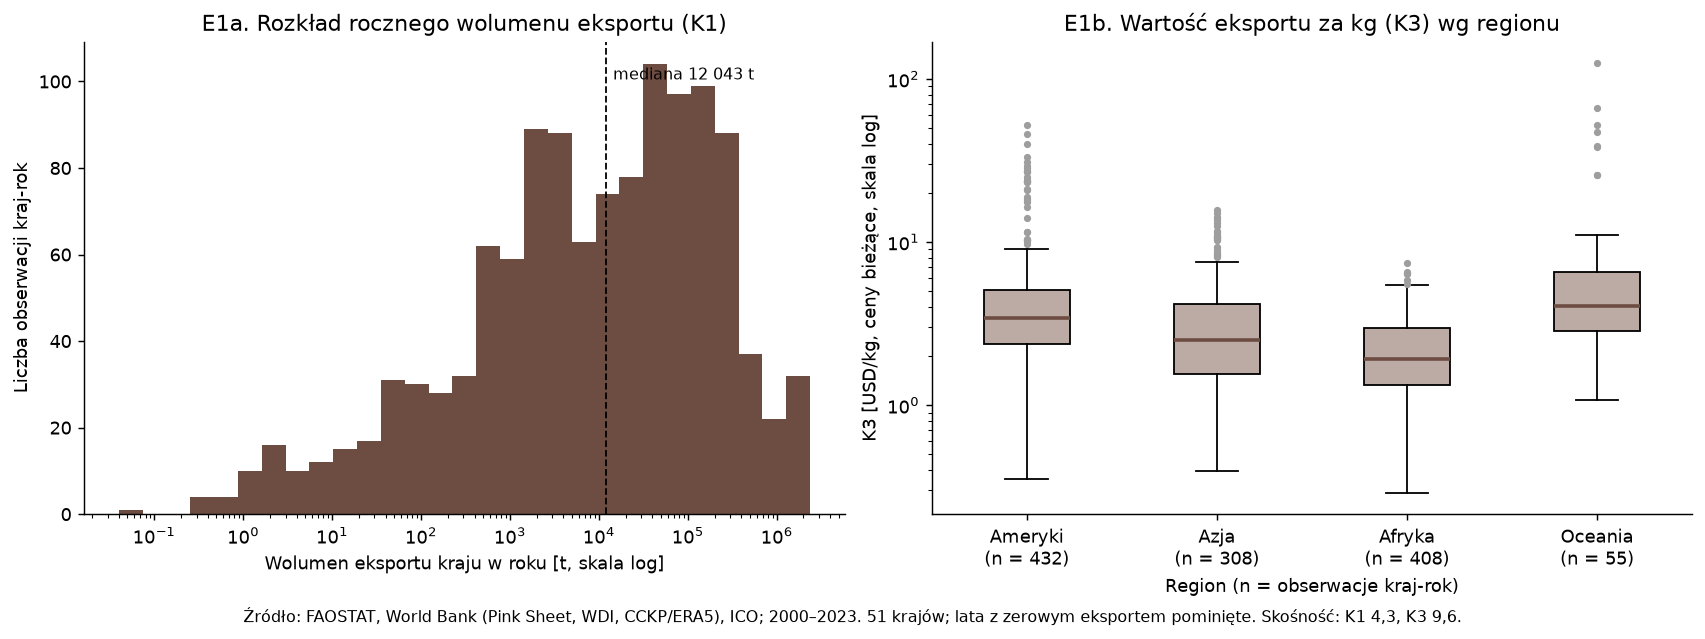

,count,min,25%,50%,75%,max
region,,,,,,
Africa,408.0,0.29,1.32,1.93,2.99,7.41
Americas,432.0,0.35,2.38,3.42,5.09,52.12
Asia,308.0,0.39,1.54,2.50,4.15,15.71
Oceania,55.0,1.08,2.84,4.04,6.54,125.00


In [8]:
volumes = kpi.loc[kpi["k1_export_t"].gt(0), "k1_export_t"]
regions = kpi.groupby("region")["k1_export_t"].sum().sort_values(ascending=False).index
k3_by_region = [kpi.loc[kpi["region"].eq(region), "k3_usd_per_kg"].dropna() for region in regions]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), layout="constrained")
axes[0].hist(volumes, bins=np.logspace(np.log10(volumes.min()), np.log10(volumes.max()), 30), color=BROWN)
axes[0].axvline(volumes.median(), color="black", linestyle="--", linewidth=1)
axes[0].text(volumes.median() * 1.2, axes[0].get_ylim()[1] * 0.92, f"mediana {number(volumes.median())} t", fontsize=9)
axes[0].set(xscale="log", title="E1a. Rozkład rocznego wolumenu eksportu (K1)",
            xlabel="Wolumen eksportu kraju w roku [t, skala log]", ylabel="Liczba obserwacji kraj-rok")
axes[1].boxplot(k3_by_region, tick_labels=[f"{REGION_PL[r]}\n(n = {len(v)})" for r, v in zip(regions, k3_by_region)],
                patch_artist=True, boxprops={"facecolor": LIGHT_BROWN}, medianprops={"color": BROWN, "linewidth": 2},
                flierprops={"markersize": 3, "markerfacecolor": GREY, "markeredgecolor": GREY})
axes[1].set(yscale="log", title="E1b. Wartość eksportu za kg (K3) wg regionu",
            xlabel="Region (n = obserwacje kraj-rok)", ylabel="K3 [USD/kg, ceny bieżące, skala log]")
fig.supxlabel(f"{SOURCE} 51 krajów; lata z zerowym eksportem pominięte. "
              f"Skośność: K1 {number(volumes.skew(), 1)}, K3 {number(kpi['k3_usd_per_kg'].skew(), 1)}.", fontsize=9)
save(fig, "e1_distributions")
display(kpi.groupby("region")["k3_usd_per_kg"].describe()[["count", "min", "25%", "50%", "75%", "max"]].round(2))

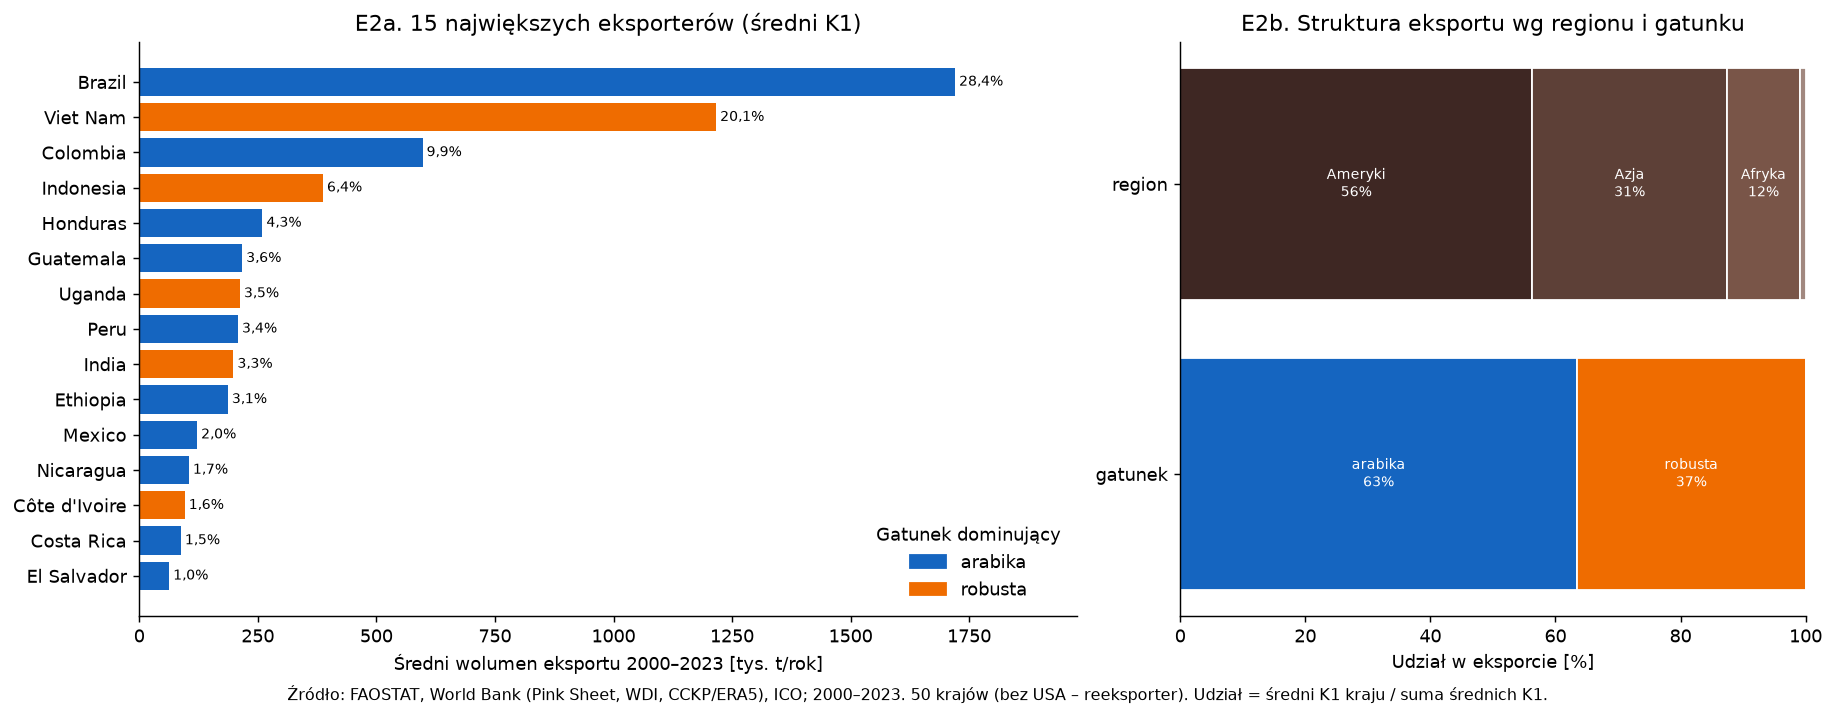

region
Americas    56.3
Asia        31.2
Africa      11.7
Oceania      0.9
Name: mean_export_t, dtype: float64

species
arabica        63.4
robusta        36.6
brak danych     0.0
Name: mean_export_t, dtype: float64

In [9]:
total_export = suppliers["mean_export_t"].sum()
top = suppliers.nlargest(15, "mean_export_t").sort_values("mean_export_t")
region_share = (suppliers.groupby("region")["mean_export_t"].sum() / total_export * 100).sort_values(ascending=False)
species_share = (suppliers.groupby(suppliers["species"].fillna("brak danych"))["mean_export_t"].sum() / total_export * 100).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), layout="constrained", gridspec_kw={"width_ratios": [1.5, 1]})
axes[0].barh(top["country"], top["mean_export_t"] / 1000, color=top["species"].map(SPECIES_COLORS).fillna(GREY))
for i, (value, share) in enumerate(zip(top["mean_export_t"] / 1000, top["mean_export_t"] / total_export * 100)):
    axes[0].text(value, i, f" {pct(share)}", va="center", fontsize=8)
axes[0].set(title="E2a. 15 największych eksporterów (średni K1)", xlabel="Średni wolumen eksportu 2000–2023 [tys. t/rok]")
axes[0].set_xlim(0, top["mean_export_t"].max() / 1000 * 1.15)
axes[0].legend(handles=[Patch(color=c, label=SPECIES_PL[s]) for s, c in SPECIES_COLORS.items()],
               title="Gatunek dominujący", frameon=False, loc="lower right")


def stacked(ax, y, shares, colors, names):
    left = 0
    for (label, share), color in zip(shares.items(), colors):
        ax.barh(y, share, left=left, color=color, edgecolor="white")
        if share >= 6:
            ax.text(left + share / 2, y, f"{names.get(label, label)}\n{pct(share, 0)}", ha="center", va="center", fontsize=8, color="white")
        left += share


stacked(axes[1], 1, region_share, ["#3E2723", "#5D4037", "#795548", "#A1887F"], REGION_PL)
stacked(axes[1], 0, species_share, [SPECIES_COLORS.get(s, GREY) for s in species_share.index], SPECIES_PL)
axes[1].set(yticks=[0, 1], yticklabels=["gatunek", "region"], xlim=(0, 100), xlabel="Udział w eksporcie [%]",
            title="E2b. Struktura eksportu wg regionu i gatunku")
fig.supxlabel(f"{SOURCE} 50 krajów (bez USA – reeksporter). Udział = średni K1 kraju / suma średnich K1.", fontsize=9)
save(fig, "e2_ranking")
display(region_share.round(1), species_share.round(1))

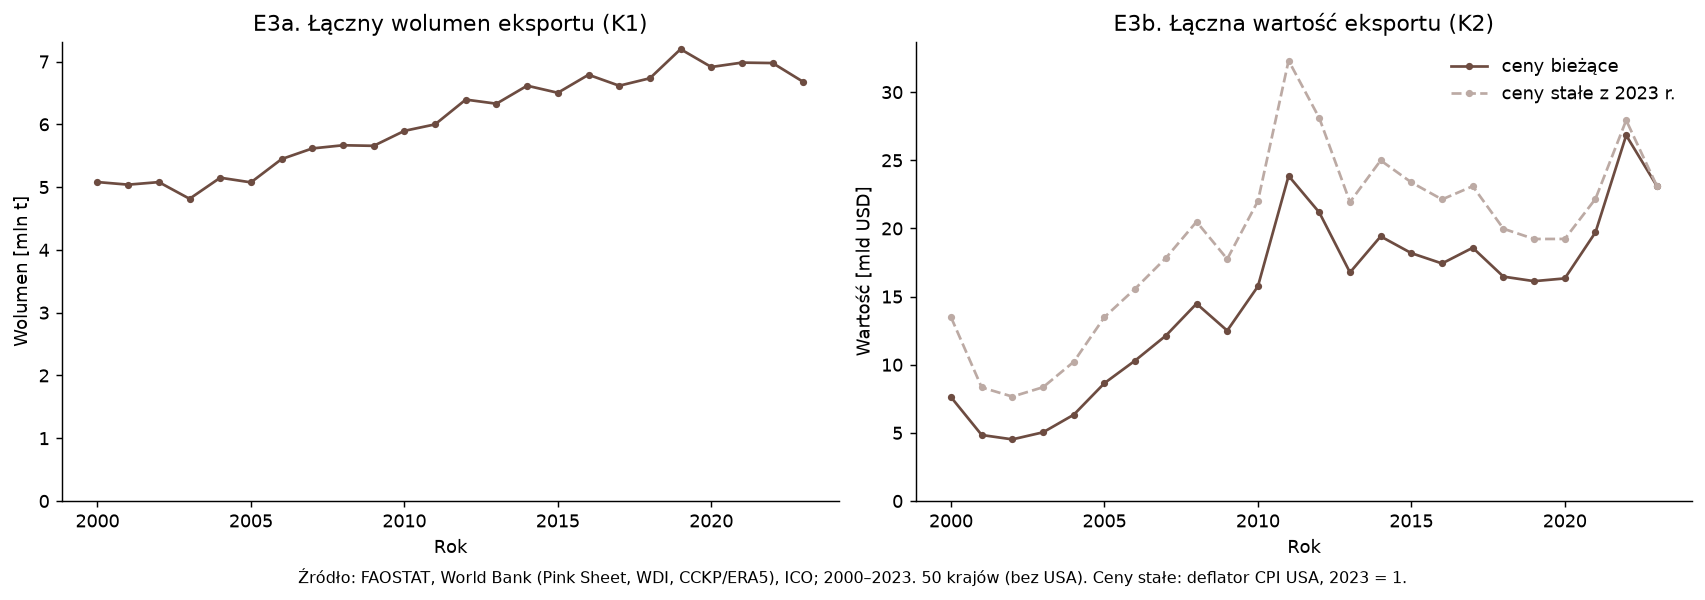

export_t           31.4
value_usd         203.3
value_usd_2023     71.4
Name: change 2000->2023 [%], dtype: float64

In [10]:
yearly = (kpi.loc[kpi["iso3"].ne("USA")].groupby("year")
          .agg(export_t=("k1_export_t", "sum"), value_usd=("k2_export_value_usd", "sum"), value_usd_2023=("k2_export_value_usd_2023", "sum")))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
axes[0].plot(yearly.index, yearly["export_t"] / 1e6, color=BROWN, marker="o", markersize=3)
axes[0].set(title="E3a. Łączny wolumen eksportu (K1)", xlabel="Rok", ylabel="Wolumen [mln t]", ylim=(0, None))
axes[1].plot(yearly.index, yearly["value_usd"] / 1e9, color=BROWN, marker="o", markersize=3, label="ceny bieżące")
axes[1].plot(yearly.index, yearly["value_usd_2023"] / 1e9, color=LIGHT_BROWN, marker="o", markersize=3, linestyle="--", label="ceny stałe z 2023 r.")
axes[1].set(title="E3b. Łączna wartość eksportu (K2)", xlabel="Rok", ylabel="Wartość [mld USD]", ylim=(0, None))
axes[1].legend(frameon=False)
fig.supxlabel(f"{SOURCE} 50 krajów (bez USA). Ceny stałe: deflator CPI USA, 2023 = 1.", fontsize=9)
save(fig, "e3_trend")
growth = (yearly.loc[END] / yearly.loc[START] - 1) * 100
display(growth.round(1).rename("change 2000->2023 [%]"))

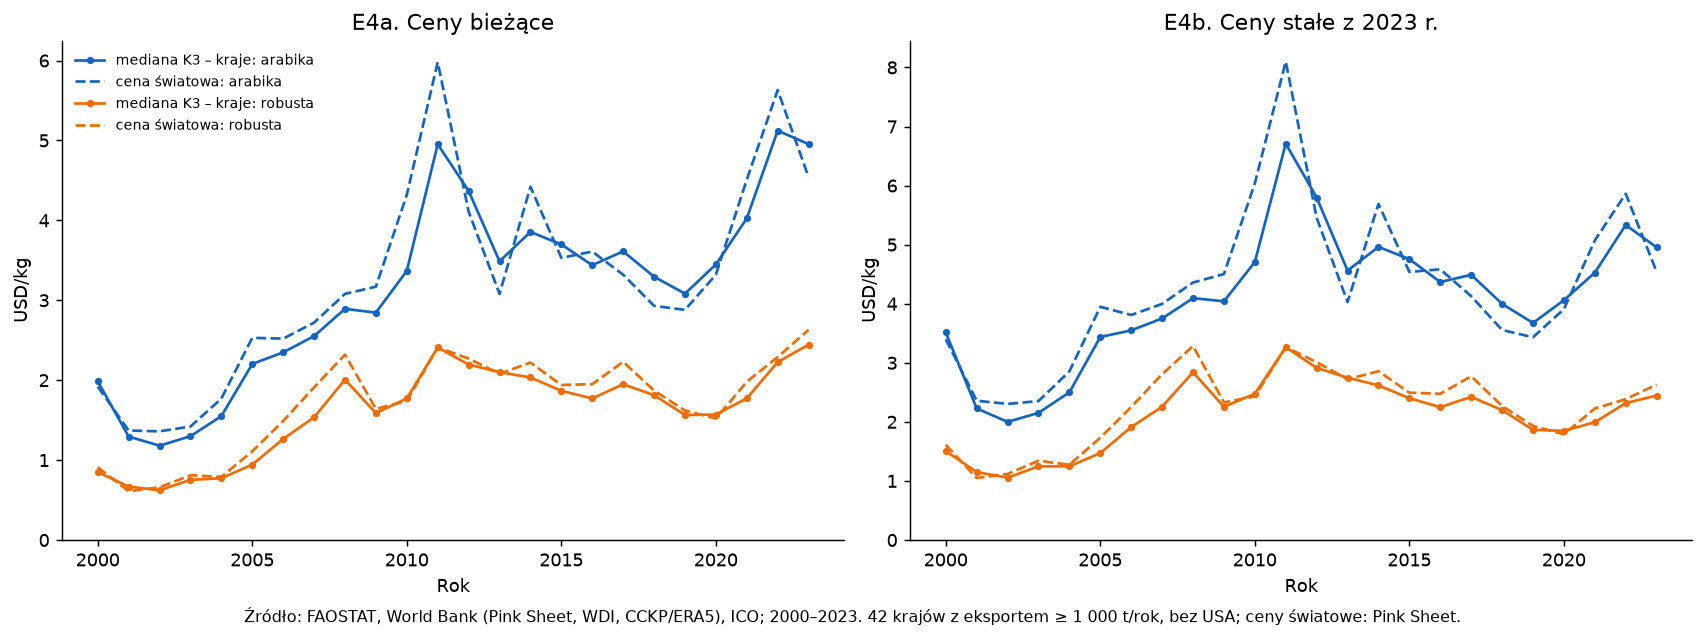

,spearman_rho,median_k3_to_world_price
arabica,0.95,0.94
robusta,0.96,0.95


In [11]:
medians = (eda.dropna(subset=["species"]).groupby(["year", "species"])
           .agg(nominal=("k3_usd_per_kg", "median"), real=("k6_usd_2023_per_kg", "median")).unstack("species"))
reference = {"nominal": dim_year.set_index("year")[["arabica_usd_kg", "robusta_usd_kg"]],
             "real": dim_year.set_index("year")[["arabica_usd_kg", "robusta_usd_kg"]].mul(dim_year.set_index("year")["to_usd_2023"], axis=0)}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), layout="constrained")
for ax, (kind, title) in zip(axes, [("nominal", "E4a. Ceny bieżące"), ("real", "E4b. Ceny stałe z 2023 r.")]):
    for species, color in SPECIES_COLORS.items():
        ax.plot(medians.index, medians[(kind, species)], color=color, marker="o", markersize=3,
                label=f"mediana K3 – kraje: {SPECIES_PL[species]}")
        ax.plot(reference[kind].index, reference[kind][f"{species}_usd_kg"], color=color, linestyle="--",
                label=f"cena światowa: {SPECIES_PL[species]}")
    ax.set(title=title, xlabel="Rok", ylabel="USD/kg")
    ax.set_ylim(bottom=0)
axes[0].legend(frameon=False, fontsize=8)
fig.supxlabel(f"{SOURCE} {len(analysed)} krajów z eksportem ≥ {number(MIN_EXPORT_T)} t/rok, bez USA; ceny światowe: Pink Sheet.", fontsize=9)
save(fig, "e4_unit_value_vs_world_price")
tracking = pd.DataFrame({species: {"spearman_rho": medians[("nominal", species)].to_frame("k3").join(reference["nominal"][f"{species}_usd_kg"]).corr(method="spearman").iloc[0, 1],
                                   "median_k3_to_world_price": (medians[("nominal", species)] / reference["nominal"][f"{species}_usd_kg"]).median()}
                         for species in SPECIES_COLORS}).T
display(tracking.round(2))

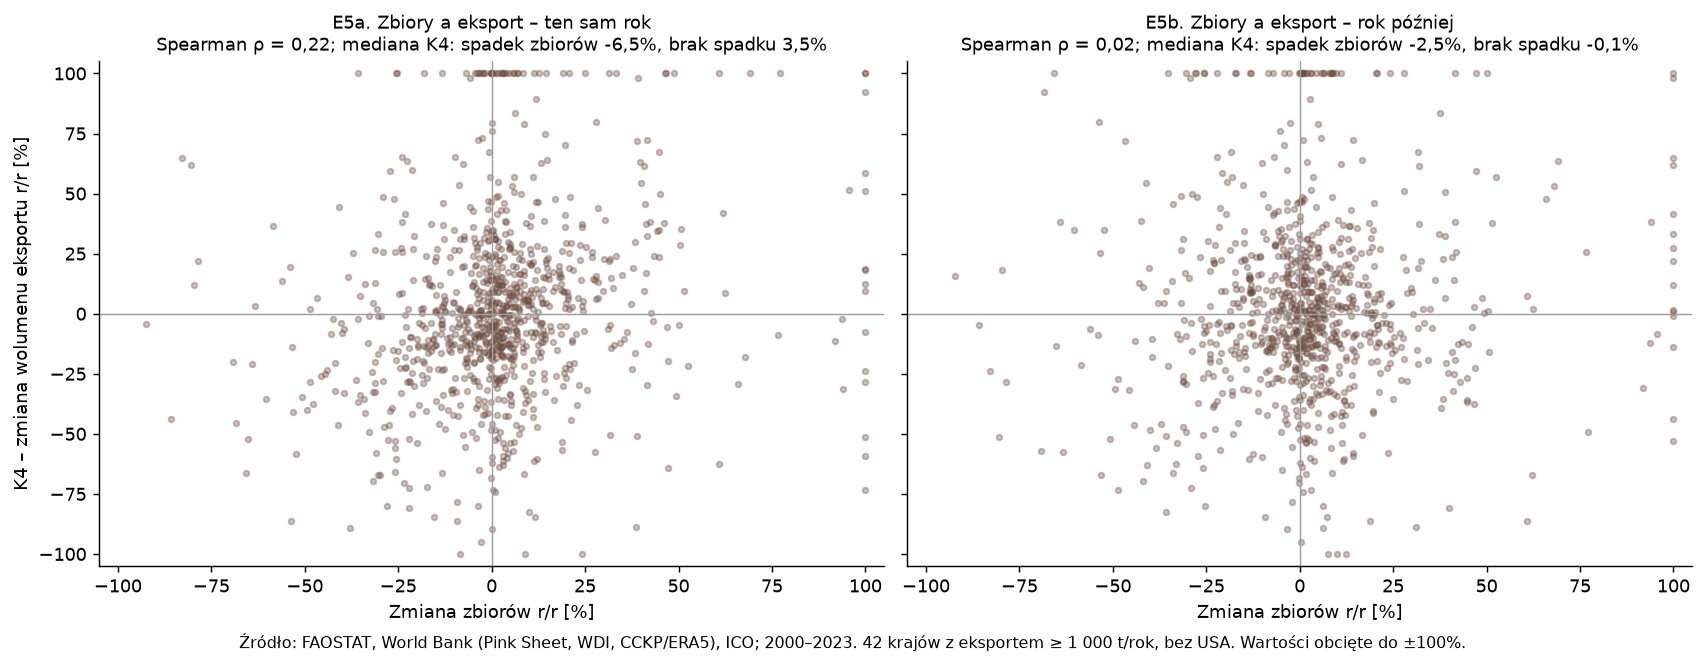

,ten sam rok,rok później
rho,0.22,0.02
median_k4_drop,-6.52,-2.47
median_k4_no_drop,3.52,-0.06
n,966.00,924.00


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained", sharey=True)
h1 = {}
for ax, (column, label, letter) in zip(axes, [("k4_export_t_yoy_pct", "ten sam rok", "a"), ("k4_next_year_pct", "rok później", "b")]):
    pair = eda[["production_yoy_pct", column]].dropna()
    drop = pair["production_yoy_pct"].lt(0)
    h1[label] = {"rho": spearman(pair, "production_yoy_pct", column),
                 "median_k4_drop": pair.loc[drop, column].median(), "median_k4_no_drop": pair.loc[~drop, column].median(), "n": len(pair)}
    ax.scatter(pair["production_yoy_pct"].clip(-100, 100), pair[column].clip(-100, 100), s=10, alpha=0.35, color=BROWN)
    ax.axhline(0, color=GREY, linewidth=0.8)
    ax.axvline(0, color=GREY, linewidth=0.8)
    ax.set_title(f"E5{letter}. Zbiory a eksport – {label}\nSpearman ρ = {number(h1[label]['rho'], 2)}; mediana K4: "
                 f"spadek zbiorów {pct(h1[label]['median_k4_drop'])}, brak spadku {pct(h1[label]['median_k4_no_drop'])}", fontsize=10)
    ax.set(
           xlabel="Zmiana zbiorów r/r [%]", xlim=(-105, 105), ylim=(-105, 105))
axes[0].set_ylabel("K4 – zmiana wolumenu eksportu r/r [%]")
fig.supxlabel(f"{SOURCE} {len(analysed)} krajów z eksportem ≥ {number(MIN_EXPORT_T)} t/rok, bez USA. Wartości obcięte do ±100%.", fontsize=9)
save(fig, "e5_harvest_vs_export")
display(pd.DataFrame(h1).round(2))

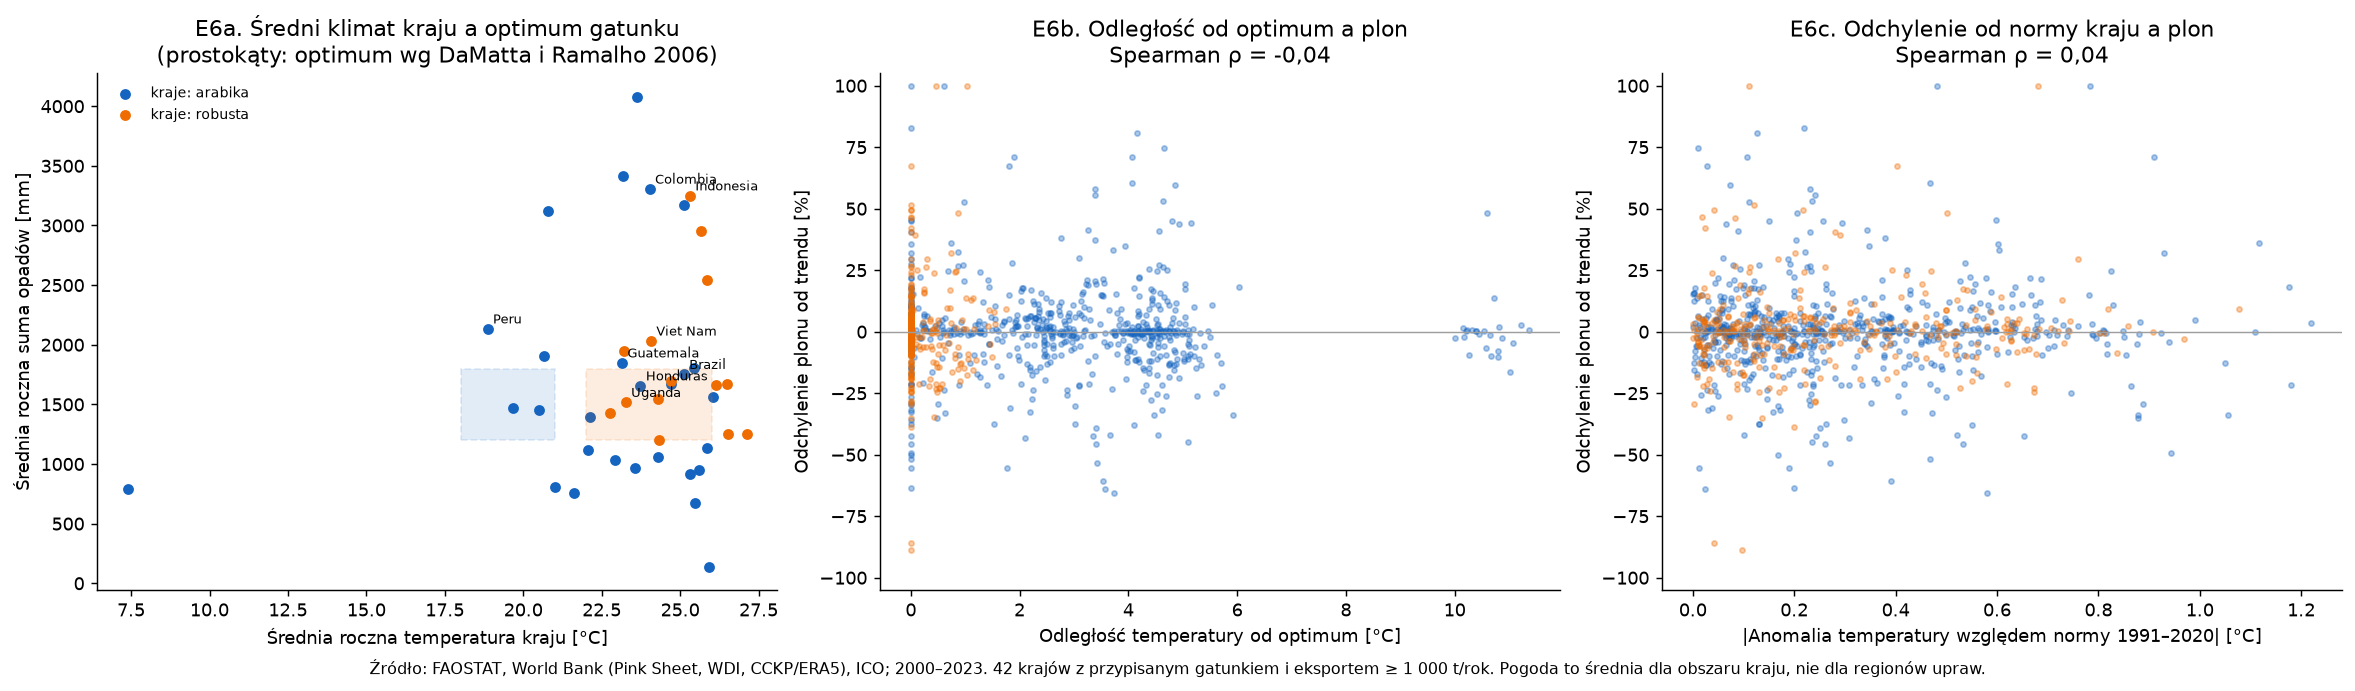

,countries,mean_temperature_inside_optimum
arabica,28,5
robusta,14,10


In [13]:
climate = (eda.dropna(subset=["species"]).groupby(["iso3", "country", "species"])
           .agg(temperature_c=("temperature_c", "mean"), precipitation_mm=("precipitation_mm", "mean"),
                mean_export_t=("k1_export_t", "mean")).reset_index())
optimum_ranges = query("SELECT * FROM ref_weather_optimum").set_index("species")
yearly_weather = eda.dropna(subset=["species"]).assign(abs_temperature_anomaly_c=lambda d: d["temperature_anomaly_c"].abs())

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), layout="constrained")
for species, row in optimum_ranges.iterrows():
    axes[0].add_patch(Rectangle((row["temperature_min_c"], row["precipitation_min_mm"]),
                                row["temperature_max_c"] - row["temperature_min_c"], row["precipitation_max_mm"] - row["precipitation_min_mm"],
                                facecolor=SPECIES_COLORS[species], alpha=0.12, edgecolor=SPECIES_COLORS[species], linestyle="--"))
    part = climate.loc[climate["species"].eq(species)]
    axes[0].scatter(part["temperature_c"], part["precipitation_mm"], color=SPECIES_COLORS[species], s=25, label=f"kraje: {SPECIES_PL[species]}")
for _, row in climate.nlargest(8, "mean_export_t").iterrows():
    axes[0].annotate(row["country"], (row["temperature_c"], row["precipitation_mm"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
axes[0].set(title="E6a. Średni klimat kraju a optimum gatunku\n(prostokąty: optimum wg DaMatta i Ramalho 2006)",
            xlabel="Średnia roczna temperatura kraju [°C]", ylabel="Średnia roczna suma opadów [mm]")
axes[0].legend(frameon=False, fontsize=8)
for ax, (column, label, title) in zip(axes[1:], [
        ("temperature_off_optimum_c", "Odległość temperatury od optimum [°C]", "E6b. Odległość od optimum a plon"),
        ("abs_temperature_anomaly_c", "|Anomalia temperatury względem normy 1991–2020| [°C]", "E6c. Odchylenie od normy kraju a plon")]):
    for species, color in SPECIES_COLORS.items():
        part = yearly_weather.loc[yearly_weather["species"].eq(species)]
        ax.scatter(part[column], part["yield_deviation_pct"].clip(-100, 100), s=8, alpha=0.35, color=color, label=SPECIES_PL[species])
    ax.axhline(0, color=GREY, linewidth=0.8)
    ax.set(title=f"{title}\nSpearman ρ = {number(spearman(yearly_weather, column, 'yield_deviation_pct'), 2)}",
           xlabel=label, ylabel="Odchylenie plonu od trendu [%]", ylim=(-105, 105))
fig.supxlabel(f"{SOURCE} {climate['iso3'].nunique()} krajów z przypisanym gatunkiem i eksportem ≥ {number(MIN_EXPORT_T)} t/rok. "
              "Pogoda to średnia dla obszaru kraju, nie dla regionów upraw.", fontsize=9)
save(fig, "e6_weather_vs_yield")
inside = {species: int(((part["temperature_c"].between(optimum_ranges.loc[species, "temperature_min_c"], optimum_ranges.loc[species, "temperature_max_c"]))).sum())
          for species, part in climate.groupby("species")}
display(pd.DataFrame({"countries": climate.groupby("species").size(), "mean_temperature_inside_optimum": pd.Series(inside)}))

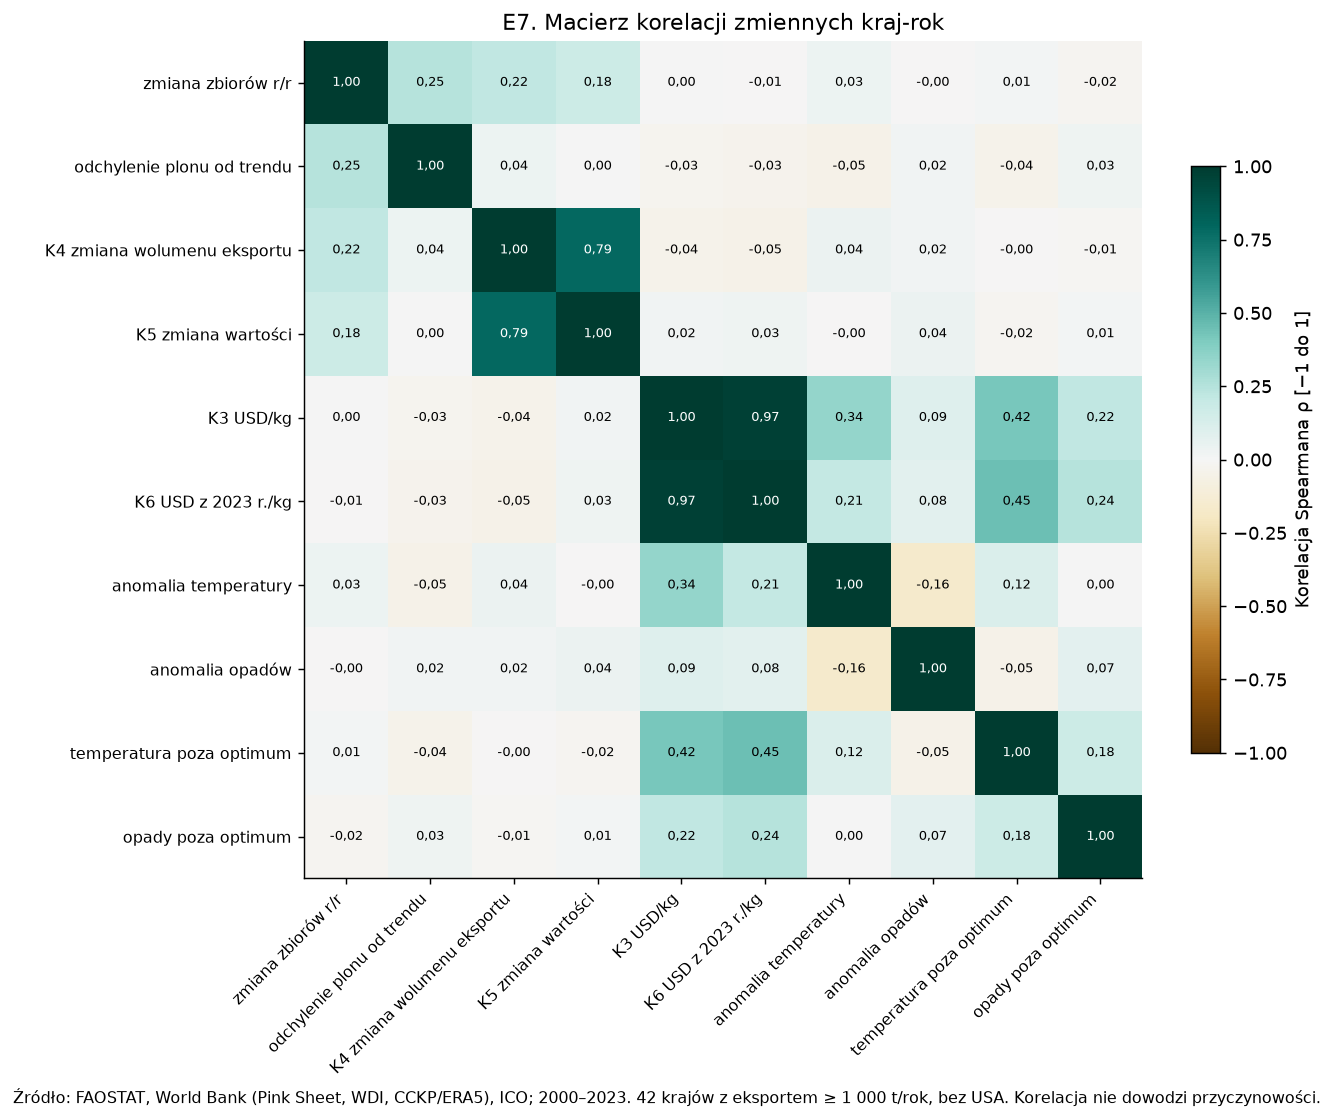

In [14]:
CORRELATION_LABELS = {
    "production_yoy_pct": "zmiana zbiorów r/r", "yield_deviation_pct": "odchylenie plonu od trendu",
    "k4_export_t_yoy_pct": "K4 zmiana wolumenu eksportu", "k5_export_value_yoy_pct": "K5 zmiana wartości",
    "k3_usd_per_kg": "K3 USD/kg",
    "k6_usd_2023_per_kg": "K6 USD z 2023 r./kg", "temperature_anomaly_c": "anomalia temperatury",
    "precipitation_anomaly_pct": "anomalia opadów", "temperature_off_optimum_c": "temperatura poza optimum",
    "precipitation_off_optimum_mm": "opady poza optimum",
}
correlation = eda[list(CORRELATION_LABELS)].corr(method="spearman").rename(index=CORRELATION_LABELS, columns=CORRELATION_LABELS)

fig, ax = plt.subplots(figsize=(10, 8.5), layout="constrained")
image = ax.imshow(correlation.to_numpy(), cmap="BrBG", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlation)), correlation.columns, rotation=45, ha="right", fontsize=9)
ax.set_yticks(range(len(correlation)), correlation.index, fontsize=9)
for i in range(len(correlation)):
    for j in range(len(correlation)):
        value = correlation.iat[i, j]
        ax.text(j, i, number(value, 2), ha="center", va="center", fontsize=7, color="white" if abs(value) > 0.6 else "black")
fig.colorbar(image, ax=ax, label="Korelacja Spearmana ρ [−1 do 1]", shrink=0.7)
ax.set_title("E7. Macierz korelacji zmiennych kraj-rok")
fig.supxlabel(f"{SOURCE} {len(analysed)} krajów z eksportem ≥ {number(MIN_EXPORT_T)} t/rok, bez USA. Korelacja nie dowodzi przyczynowości.", fontsize=9)
save(fig, "e7_correlation")

In [15]:
def verdict(condition):
    return "wstępnie potwierdzona" if condition else "wstępnie niepotwierdzona"


rows = []
for threshold in [0, -10]:
    for column, label in [("k4_export_t_yoy_pct", "ten sam rok"), ("k4_next_year_pct", "rok później")]:
        pair = eda[["production_yoy_pct", column]].dropna()
        weak = pair["production_yoy_pct"].lt(threshold)
        weak_median, other_median = pair.loc[weak, column].median(), pair.loc[~weak, column].median()
        rows.append(["H1", f"słabsze zbiory: r/r < {threshold}%, {label}",
                     f"mediana K4: słabsze zbiory {pct(weak_median)} (n = {weak.sum()}), pozostałe lata {pct(other_median)} (n = {(~weak).sum()})",
                     verdict(weak_median < other_median)])

volume_drop = eda.loc[eda["k4_export_t_yoy_pct"].lt(0)]
for column, label in [("k5_export_value_usd_2023_yoy_pct", "ceny stałe"), ("k5_export_value_yoy_pct", "ceny bieżące")]:
    share = volume_drop[column].ge(0).mean() * 100
    rows.append(["H2", f"wartość eksportu w latach ze spadkiem K1, {label}",
                 f"wartość nie spadła w {pct(share)} z {len(volume_drop)} lat ze spadkiem wolumenu", verdict(share >= 50)])

weather_years = eda.dropna(subset=["weather_in_optimum"])
in_optimum = weather_years["weather_in_optimum"].eq(1)
rows.append(["H3", "optimum wg literatury",
             f"mediana odchylenia plonu: pogoda w optimum {pct(weather_years.loc[in_optimum, 'yield_deviation_pct'].median())} "
             f"(n = {in_optimum.sum()}), poza optimum {pct(weather_years.loc[~in_optimum, 'yield_deviation_pct'].median())} (n = {(~in_optimum).sum()})",
             verdict(weather_years.loc[in_optimum, "yield_deviation_pct"].median() - weather_years.loc[~in_optimum, "yield_deviation_pct"].median() >= 1)])
local = eda.assign(abs_temperature=eda["temperature_anomaly_c"].abs(), abs_precipitation=eda["precipitation_anomaly_pct"].abs())
rho_temperature, rho_precipitation = spearman(local, "abs_temperature", "yield_deviation_pct"), spearman(local, "abs_precipitation", "yield_deviation_pct")
in_norm = eda["weather_in_norm"].eq(1)
norm_median, off_norm_median = eda.loc[in_norm, "yield_deviation_pct"].median(), eda.loc[~in_norm, "yield_deviation_pct"].median()
rows.append(["H3", "pogoda w normie kraju 1991–2020 (definicja K8)",
             f"mediana odchylenia plonu: w normie {pct(norm_median)} (n = {in_norm.sum()}), poza normą {pct(off_norm_median)} "
             f"(n = {(~in_norm).sum()}); Spearman ρ z |anomalią temperatury| = {number(rho_temperature, 2)}, "
             f"z |anomalią opadów| = {number(rho_precipitation, 2)}",
             verdict(norm_median - off_norm_median >= 1)])

periods = {"2000–2004": eda["year"].between(START, START + 4), "2019–2023": eda["year"].between(END - 4, END)}
unit_value = {name: {"nominal": eda.loc[mask, "k2_export_value_usd"].sum() / (eda.loc[mask, "k1_export_t"].sum() * 1000),
                     "real": eda.loc[mask, "k2_export_value_usd_2023"].sum() / (eda.loc[mask, "k1_export_t"].sum() * 1000)}
              for name, mask in periods.items()}
nominal_change = (unit_value["2019–2023"]["nominal"] / unit_value["2000–2004"]["nominal"] - 1) * 100
real_change = (unit_value["2019–2023"]["real"] / unit_value["2000–2004"]["real"] - 1) * 100
rows.append(["Pytanie 6", "średnia wartość za kg, 2000–2004 → 2019–2023",
             f"nominalnie {number(unit_value['2000–2004']['nominal'], 2)} → {number(unit_value['2019–2023']['nominal'], 2)} USD/kg ({pct(nominal_change, 0)}), "
             f"realnie {number(unit_value['2000–2004']['real'], 2)} → {number(unit_value['2019–2023']['real'], 2)} USD z 2023 r./kg ({pct(real_change, 0)})",
             f"inflacja odpowiada za ok. {pct((nominal_change - real_change) / nominal_change * 100, 0)} wzrostu nominalnego"])
hypotheses = pd.DataFrame(rows, columns=["hipoteza", "wariant", "wynik", "ocena"])
save_table(hypotheses, "hypotheses")

,hipoteza,wariant,wynik,ocena
0,H1,"słabsze zbiory: r/r < 0%, ten sam rok","mediana K4: słabsze zbiory -6,5% (n = 433), pozostałe lata 3,5% (n = 533)",wstępnie potwierdzona
1,H1,"słabsze zbiory: r/r < 0%, rok później","mediana K4: słabsze zbiory -2,5% (n = 412), pozostałe lata -0,1% (n = 512)",wstępnie potwierdzona
2,H1,"słabsze zbiory: r/r < -10%, ten sam rok","mediana K4: słabsze zbiory -12,8% (n = 223), pozostałe lata 1,7% (n = 743)",wstępnie potwierdzona
3,H1,"słabsze zbiory: r/r < -10%, rok później","mediana K4: słabsze zbiory -3,6% (n = 214), pozostałe lata -0,4% (n = 710)",wstępnie potwierdzona
4,H2,"wartość eksportu w latach ze spadkiem K1, ceny stałe","wartość nie spadła w 20,8% z 499 lat ze spadkiem wolumenu",wstępnie niepotwierdzona
5,H2,"wartość eksportu w latach ze spadkiem K1, ceny bieżące","wartość nie spadła w 24,6% z 499 lat ze spadkiem wolumenu",wstępnie niepotwierdzona
6,H3,optimum wg literatury,"mediana odchylenia plonu: pogoda w optimum 0,1% (n = 166), poza optimum 0,1% (n = 842)",wstępnie niepotwierdzona
7,H3,pogoda w normie kraju 1991–2020 (definicja K8),"mediana odchylenia plonu: w normie 0,1% (n = 491), poza normą 0,1% (n = 517); Spearman ρ z |anomalią temperatury| = 0,04, z |anomalią opadów| = 0,05",wstępnie niepotwierdzona
8,Pytanie 6,"średnia wartość za kg, 2000–2004 → 2019–2023","nominalnie 1,13 → 2,94 USD/kg (161%), realnie 1,91 → 3,21 USD z 2023 r./kg (68%)",inflacja odpowiada za ok. 58% wzrostu nominalnego


In [16]:
ratio = kpi["k3_usd_per_kg"] / kpi["reference_usd_kg"]
flagged = kpi.assign(ratio=ratio).merge(review.loc[review["rule"].eq("R10"), ["iso3", "year"]], on=["iso3", "year"])
flagged = flagged.merge(kpi_country[["iso3", "mean_export_t"]], on="iso3")
flagged["category"] = np.select(
    [flagged["mean_export_t"].lt(MIN_EXPORT_T), flagged["ratio"].gt(2)],
    [f"znikomy wolumen (< {number(MIN_EXPORT_T)} t/rok)", "K3 powyżej 2 × ceny referencyjnej"],
    "K3 poniżej 0,5 × ceny referencyjnej")
outliers = (flagged.groupby(["category", "country"])
            .agg(lata=("year", "size"), sredni_eksport_t=("mean_export_t", "first"), mediana_k3_do_ceny=("ratio", "median"))
            .reset_index().sort_values(["category", "lata"], ascending=[True, False]))
outliers["sredni_eksport_t"] = outliers["sredni_eksport_t"].map(number)
outliers["mediana_k3_do_ceny"] = outliers["mediana_k3_do_ceny"].map(lambda v: number(v, 2))
outliers.columns = ["kategoria", "kraj", "lata z flagą R10", "średni eksport [t/rok]", "mediana K3 / cena referencyjna"]
save_table(outliers, "outliers")
display(flagged.groupby("category").agg(rows=("iso3", "size"), countries=("iso3", "nunique")))

,kategoria,kraj,lata z flagą R10,średni eksport [t/rok],mediana K3 / cena referencyjna
3,"K3 poniżej 0,5 × ceny referencyjnej",Timor-Leste,9,9 186,"0,26"
1,"K3 poniżej 0,5 × ceny referencyjnej",Guinea,7,11 397,"0,34"
4,"K3 poniżej 0,5 × ceny referencyjnej",Togo,5,6 003,"0,25"
0,"K3 poniżej 0,5 × ceny referencyjnej",Ecuador,2,12 680,"0,48"
2,"K3 poniżej 0,5 × ceny referencyjnej",Madagascar,2,4 554,"0,42"
5,"K3 poniżej 0,5 × ceny referencyjnej",United Republic of Tanzania,2,52 497,"0,46"
6,"K3 poniżej 0,5 × ceny referencyjnej",Zimbabwe,2,1 298,"0,45"
11,K3 powyżej 2 × ceny referencyjnej,Jamaica,24,1 025,"8,03"
15,K3 powyżej 2 × ceny referencyjnej,Thailand,12,9 302,"2,81"
16,K3 powyżej 2 × ceny referencyjnej,Yemen,8,2 309,"2,45"


,rows,countries
category,,
"K3 poniżej 0,5 × ceny referencyjnej",29,7
K3 powyżej 2 × ceny referencyjnej,59,10
znikomy wolumen (< 1 000 t/rok),62,5


In [17]:
KPIS = [
    ("K1", "Wolumen eksportu", "ilość wyeksportowanej zielonej kawy", "t", "FAOSTAT TCL",
     "skala podaży: czy kraj udźwignie dodatkowe zamówienia", ["k1_export_t"]),
    ("K2", "Wartość eksportu", "wartość eksportu przeliczona z 1000 USD; także w cenach stałych z 2023 r.", "USD", "FAOSTAT TCL, World Bank WDI",
     "waga kawy w handlu kraju; tło dla K5", ["k2_export_value_usd", "k2_export_value_usd_2023"]),
    ("K3", "Wartość za kilogram", "K2 / (K1 × 1000); brak wyniku przy zerowym wolumenie", "USD/kg", "FAOSTAT TCL",
     "średni poziom cen eksportowych kraju – punkt odniesienia w negocjacjach", ["k3_usd_per_kg"]),
    ("K4", "Zmiana wolumenu", "100 × (K1 / K1 z poprzedniego roku − 1); brak wyniku przy zerowej podstawie", "% r/r", "FAOSTAT TCL",
     "stabilność dostaw rok do roku", ["k4_export_t_yoy_pct"]),
    ("K5", "Zmiana wartości", "100 × (K2 / K2 z poprzedniego roku − 1); także w cenach stałych", "% r/r", "FAOSTAT TCL, World Bank WDI",
     "czy spadek ilości jest rekompensowany ceną (H2)", ["k5_export_value_yoy_pct", "k5_export_value_usd_2023_yoy_pct"]),
    ("K6", "Wartość za kilogram w cenach stałych", "K3 × CPI USA (2023) / CPI USA (rok)", "USD z 2023 r./kg", "FAOSTAT TCL, World Bank WDI",
     "czy kraj drożeje realnie, czy tylko przez inflację", ["k6_usd_2023_per_kg"]),
    ("K7", "Korelacja pogody z plonem", "korelacja Pearsona temperatury (osobno: opadów) z plonem po usunięciu trendów liniowych, 24 lata",
     "r (−1 do 1)", "FAOSTAT QCL, CCKP/ERA5", "wrażliwość zbiorów na pogodę – kontekst ryzyka", ["k7_yield_temperature_r", "k7_yield_precipitation_r"]),
    ("K8", "Pogoda w normie", "% lat, w których temperatura i opady mieszczą się w ±1 odchyleniu standardowym normy kraju z lat 1991–2020",
     "% lat", "CCKP/ERA5", "jak często kraj ma nietypową pogodę – kontekst ryzyka", ["k8_weather_in_norm_pct"]),
    ("K9", "Odchylenie pogody od normy", "√(średnia kwadratów anomalii względem średniej kraju 1991–2020); osobno temperatura i opady",
     "°C; %", "CCKP/ERA5", "skala nietypowej pogody – kontekst ryzyka", ["k9_temperature_anomaly_rms_c", "k9_precipitation_anomaly_rms_pct"]),
    ("K10", "Odporność eksportu", "mediana K4 w latach, w których zbiory spadły o ponad 10% r/r", "% r/r", "FAOSTAT QCL, FAOSTAT TCL",
     "czy kraj utrzymuje eksport mimo słabszych zbiorów – główne kryterium wyboru dostawcy (cel SMART, pytanie 2)",
     ["k10_export_resilience_pct", "weak_harvest_years"]),
    ("M1", "Rozdział zmiany wartości (pomocnicza)", "efekt ilości ΔQ·(P₀+P₁)/2 i efekt ceny ΔP·(Q₀+Q₁)/2, gdzie Q = K1 [kg], P = K3; suma = zmiana K2",
     "USD", "FAOSTAT TCL", "czy wartość eksportu zmienia się przez ilość czy przez cenę (pytanie 1)",
     ["value_change_volume_effect_usd", "value_change_price_effect_usd"]),
]
save_table(pd.DataFrame([kpi_row[:6] for kpi_row in KPIS],
                        columns=["KPI", "nazwa", "definicja", "jednostka", "źródło", "znaczenie biznesowe"]), "kpi")

country_level = kpi_country.loc[kpi_country["iso3"].isin(analysed)]
values = []
for code, *_, columns in KPIS:
    for column in columns:
        view, frame, period = (("v_kpi_country", country_level, f"{START}–{END}") if column in kpi_country
                               else ("v_kpi_country_year", eda.loc[eda["year"].eq(END)], str(END)))
        median = frame[column].median()
        values.append({"KPI": code, "kolumna w bazie": f"{view}.{column}", "okres": period,
                       f"mediana ({len(analysed)} krajów)": number(median, 0 if abs(median) >= 100 else 2)})
save_table(pd.DataFrame(values), "kpi_values")
display(country_level.nlargest(10, "mean_export_t")[["country", "mean_export_t", "k8_weather_in_norm_pct", "k9_temperature_anomaly_rms_c",
                                                      "k10_export_resilience_pct", "weak_harvest_years"]].round(2))

,KPI,nazwa,definicja,jednostka,źródło,znaczenie biznesowe
0,K1,Wolumen eksportu,ilość wyeksportowanej zielonej kawy,t,FAOSTAT TCL,skala podaży: czy kraj udźwignie dodatkowe zamówienia
1,K2,Wartość eksportu,wartość eksportu przeliczona z 1000 USD; także w cenach stałych z 2023 r.,USD,"FAOSTAT TCL, World Bank WDI",waga kawy w handlu kraju; tło dla K5
2,K3,Wartość za kilogram,K2 / (K1 × 1000); brak wyniku przy zerowym wolumenie,USD/kg,FAOSTAT TCL,średni poziom cen eksportowych kraju – punkt odniesienia w negocjacjach
3,K4,Zmiana wolumenu,100 × (K1 / K1 z poprzedniego roku − 1); brak wyniku przy zerowej podstawie,% r/r,FAOSTAT TCL,stabilność dostaw rok do roku
4,K5,Zmiana wartości,100 × (K2 / K2 z poprzedniego roku − 1); także w cenach stałych,% r/r,"FAOSTAT TCL, World Bank WDI",czy spadek ilości jest rekompensowany ceną (H2)
5,K6,Wartość za kilogram w cenach stałych,K3 × CPI USA (2023) / CPI USA (rok),USD z 2023 r./kg,"FAOSTAT TCL, World Bank WDI","czy kraj drożeje realnie, czy tylko przez inflację"
6,K7,Korelacja pogody z plonem,"korelacja Pearsona temperatury (osobno: opadów) z plonem po usunięciu trendów liniowych, 24 lata",r (−1 do 1),"FAOSTAT QCL, CCKP/ERA5",wrażliwość zbiorów na pogodę – kontekst ryzyka
7,K8,Pogoda w normie,"% lat, w których temperatura i opady mieszczą się w ±1 odchyleniu standardowym normy kraju z lat 1991–2020",% lat,CCKP/ERA5,jak często kraj ma nietypową pogodę – kontekst ryzyka
8,K9,Odchylenie pogody od normy,√(średnia kwadratów anomalii względem średniej kraju 1991–2020); osobno temperatura i opady,°C; %,CCKP/ERA5,skala nietypowej pogody – kontekst ryzyka
9,K10,Odporność eksportu,"mediana K4 w latach, w których zbiory spadły o ponad 10% r/r",% r/r,"FAOSTAT QCL, FAOSTAT TCL","czy kraj utrzymuje eksport mimo słabszych zbiorów – główne kryterium wyboru dostawcy (cel SMART, pytanie 2)"


,KPI,kolumna w bazie,okres,mediana (42 krajów)
0,K1,v_kpi_country_year.k1_export_t,2023,14 920
1,K2,v_kpi_country_year.k2_export_value_usd,2023,51 560 500
2,K2,v_kpi_country_year.k2_export_value_usd_2023,2023,51 560 500
3,K3,v_kpi_country_year.k3_usd_per_kg,2023,"4,24"
4,K4,v_kpi_country_year.k4_export_t_yoy_pct,2023,"-6,86"
5,K5,v_kpi_country_year.k5_export_value_yoy_pct,2023,"-15,02"
6,K5,v_kpi_country_year.k5_export_value_usd_2023_yoy_pct,2023,"-18,38"
7,K6,v_kpi_country_year.k6_usd_2023_per_kg,2023,"4,24"
8,K7,v_kpi_country.k7_yield_temperature_r,2000–2023,"-0,13"
9,K7,v_kpi_country.k7_yield_precipitation_r,2000–2023,"-0,04"


,country,mean_export_t,k8_weather_in_norm_pct,k9_temperature_anomaly_rms_c,k10_export_resilience_pct,weak_harvest_years
2,Brazil,1720139.97,45.83,0.31,-3.78,7
46,Viet Nam,1216393.72,45.83,0.41,-18.36,2
7,Colombia,597458.37,58.33,0.37,-1.02,3
17,Indonesia,387410.79,50.00,0.30,NaN,0
15,Honduras,259647.69,50.00,0.45,-19.80,4
14,Guatemala,217095.68,33.33,0.52,-10.68,2
44,Uganda,212240.84,50.00,0.40,-12.92,3
33,Peru,208131.25,50.00,0.32,-23.34,5
18,India,198559.38,54.17,0.28,4.93,1
12,Ethiopia,186799.25,45.83,0.37,7.51,3
